# Task 4 · Unveiling the Android App Market (Google Play Store Analysis)

**Objective:** Clean the messy, real-world Google Play Store data, explore categories, ratings, size, installs and pricing, run sentiment analysis on user reviews, and finish with data-driven advice for a developer planning to launch a new app.

**Datasets** (place both CSVs in the same folder as this notebook; the loader also accepts files with a prefix in the name, such as `1791..._googleplaystore.csv`):
- `googleplaystore.csv`: app metadata (category, rating, size, installs, price...)
- `googleplaystore_user_reviews.csv`: individual user reviews

**Setup:** `pip install -r req.txt`

In [ ]:
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

ModuleNotFoundError: No module named 'vaderSentiment'

## 1. Load the two datasets separately

In [ ]:
def find_file(suffix):
    """Find a CSV in the current folder whose name ends with `suffix`."""
    matches = glob.glob(f"*{suffix}")
    if not matches:
        raise FileNotFoundError(f"Could not find a file ending with '{suffix}' in the current folder.")
    return matches[0]

APPS_PATH = find_file("googleplaystore.csv")
REVIEWS_PATH = find_file("googleplaystore_user_reviews.csv")
print("Apps file    :", APPS_PATH)
print("Reviews file :", REVIEWS_PATH)

apps_raw = pd.read_csv(APPS_PATH)
reviews_raw = pd.read_csv(REVIEWS_PATH)

print(f"\nApps dataset   : {apps_raw.shape[0]:,} rows x {apps_raw.shape[1]} columns")
print(f"Reviews dataset: {reviews_raw.shape[0]:,} rows x {reviews_raw.shape[1]} columns")
apps_raw.head()

Apps file    : 1791604384174_googleplaystore.csv
Reviews file : 1791604384173_googleplaystore_user_reviews.csv

Apps dataset   : 10,841 rows x 13 columns
Reviews dataset: 64,295 rows x 5 columns


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.90,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.70,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.50,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.30,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [ ]:
reviews_raw.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.53
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.29
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.88
4,10 Best Foods for You,Best idea us,Positive,1.00,0.30


## 2. Data cleaning

First, a quick audit of what is wrong with the raw data.

In [ ]:
audit = pd.DataFrame({
    "dtype": apps_raw.dtypes.astype(str),
    "nulls": apps_raw.isnull().sum(),
    "null %": (apps_raw.isnull().mean() * 100).round(1),
})
display(audit)
print(f"Fully duplicated rows        : {apps_raw.duplicated().sum():,}")
print(f"Rows sharing an app name     : {apps_raw['App'].duplicated().sum():,}")
print("\nSample of columns stored as text that should be numeric:")
print(apps_raw[["Reviews", "Size", "Installs", "Price"]].sample(5, random_state=1).to_string())

,dtype,nulls,null %
App,str,0,0.00
Category,str,0,0.00
Rating,float64,1474,13.60
Reviews,str,0,0.00
Size,str,0,0.00
Installs,str,0,0.00
Type,str,1,0.00
Price,str,0,0.00
Content Rating,str,1,0.00
Genres,str,0,0.00


Fully duplicated rows        : 483
Rows sharing an app name     : 1,181

Sample of columns stored as text that should be numeric:
     Reviews  Size    Installs Price
4970     999   91k    100,000+     0
7351    9950   15M    500,000+     0
6868       9  4.2M        100+     0
3407   37237  3.9M  5,000,000+     0
4324   45224   49M  5,000,000+     0


**Problems found and how they are fixed**

| Problem | Fix |
|---|---|
| One malformed row whose columns are shifted (category shows `1.9`, rating `19`) | Dropped, since the values cannot be reliably realigned |
| `Installs` is text like `10,000+` | Strip `+` and `,`, convert to integer (the value is the *minimum* of the install bucket) |
| `Price` is text like `$2.99` | Strip `$`, convert to float |
| `Size` is text like `19M`, `201k`, `Varies with device` | Convert to megabytes; "Varies with device" becomes null (no real size exists) |
| `Reviews` is text | Convert to integer |
| `Last Updated` is text | Convert to datetime |
| `Type` has a null and a stray `0` | Re-derived from `Price` (price > 0 means Paid) |
| Duplicate apps (the same app listed several times) | Keep one row per app: the one with the most reviews (the most recent snapshot) |
| `Rating` has about 14% nulls | **Kept as null.** These are apps with no ratings yet; imputing a value would invent data. Rating analyses simply use rated apps |

In [ ]:
apps = apps_raw.copy()

# 1) Remove the malformed row(s): a valid category is upper-case letters/underscores only
bad_rows = ~apps["Category"].astype(str).str.match(r"^[A-Z_]+$")
print(f"Malformed rows removed: {bad_rows.sum()}  ->", apps.loc[bad_rows, "App"].tolist())
apps = apps.loc[~bad_rows].copy()

# 2) Fix data types
apps["Reviews"] = pd.to_numeric(apps["Reviews"], errors="coerce").astype("Int64")

apps["Installs"] = pd.to_numeric(apps["Installs"].str.replace(r"[+,]", "", regex=True), errors="coerce")

apps["Price"] = pd.to_numeric(apps["Price"].str.replace("$", "", regex=False), errors="coerce")

def size_to_mb(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if value.endswith("M"):
        return float(value[:-1].replace(",", ""))
    if value.endswith("k"):
        return float(value[:-1].replace(",", "")) / 1024
    return np.nan                      # 'Varies with device'
apps["Size_MB"] = apps["Size"].map(size_to_mb)

apps["Last Updated"] = pd.to_datetime(apps["Last Updated"], errors="coerce")

# Ratings must be between 1 and 5
apps.loc[~apps["Rating"].between(1, 5), "Rating"] = np.nan

# 3) Re-derive Type from Price (fixes the null and the stray '0')
apps["Type"] = np.where(apps["Price"] > 0, "Paid", "Free")

# 4) Remove duplicates: one row per app, keeping the row with the most reviews
before = len(apps)
exact_dups = apps.duplicated().sum()
apps = (apps.sort_values("Reviews", ascending=False)
            .drop_duplicates(subset="App", keep="first")
            .sort_index()
            .reset_index(drop=True))
print(f"Duplicates removed: {before - len(apps):,} rows ({exact_dups:,} exact copies + the rest were older snapshots of the same app)")

# 5) Tidy-up: the original text columns are no longer needed
apps = apps.drop(columns=["Size"])
print(f"\nClean apps dataset: {apps.shape[0]:,} unique apps")

Malformed rows removed: 1  -> ['Life Made WI-Fi Touchscreen Photo Frame']
Duplicates removed: 1,181 rows (483 exact copies + the rest were older snapshots of the same app)

Clean apps dataset: 9,659 unique apps


In [ ]:
print("Remaining nulls after cleaning:")
remaining = apps.isnull().sum()
display(remaining[remaining > 0].to_frame("nulls"))
print("\nCleaned data types:")
display(apps.dtypes.astype(str).to_frame("dtype").T)
apps.head()

Remaining nulls after cleaning:


,nulls
Rating,1463
Current Ver,8
Android Ver,2
Size_MB,1228



Cleaned data types:


,App,Category,Rating,Reviews,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB
dtype,str,str,float64,Int64,int64,str,float64,str,str,datetime64[us],str,str,float64


,App,Category,Rating,Reviews,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159,10000,Free,0.00,Everyone,Art & Design,2018-01-07,1.0.0,4.0.3 and up,19.00
1,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.70,87510,5000000,Free,0.00,Everyone,Art & Design,2018-08-01,1.2.4,4.0.3 and up,8.70
2,Sketch - Draw & Paint,ART_AND_DESIGN,4.50,215644,50000000,Free,0.00,Teen,Art & Design,2018-06-08,Varies with device,4.2 and up,25.00
3,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.30,967,100000,Free,0.00,Everyone,Art & Design;Creativity,2018-06-20,1.1,4.4 and up,2.80
4,Paper flowers instructions,ART_AND_DESIGN,4.40,167,50000,Free,0.00,Everyone,Art & Design,2017-03-26,1.0,2.3 and up,5.60


The nulls that remain are deliberate: `Rating` (unrated apps), `Size_MB` ("Varies with device") and a few version fields. Each analysis below drops only the nulls in the columns it actually uses.

### Cleaning the reviews dataset

In [ ]:
reviews = reviews_raw.copy()
print(f"Reviews with no text: {reviews['Translated_Review'].isnull().sum():,} "
      f"({reviews['Translated_Review'].isnull().mean()*100:.0f}% of rows)")

reviews = reviews.dropna(subset=["Translated_Review"])               # nothing to analyse without text
n_before = len(reviews)
reviews = reviews.drop_duplicates(subset=["App", "Translated_Review"])  # same review repeated
print(f"Duplicate reviews removed: {n_before - len(reviews):,}")
reviews = reviews.reset_index(drop=True)
print(f"Clean reviews dataset: {len(reviews):,} reviews across {reviews['App'].nunique():,} apps")

Reviews with no text: 26,868 (42% of rows)
Duplicate reviews removed: 7,735
Clean reviews dataset: 29,692 reviews across 865 apps


## 3. Category analysis

Which categories hold the most apps, and which are the most **saturated**?
Saturation is judged two ways: how many apps compete in the category, and how much demand (installs) there is per app.

33 categories. The top 5 categories hold 46% of all apps.


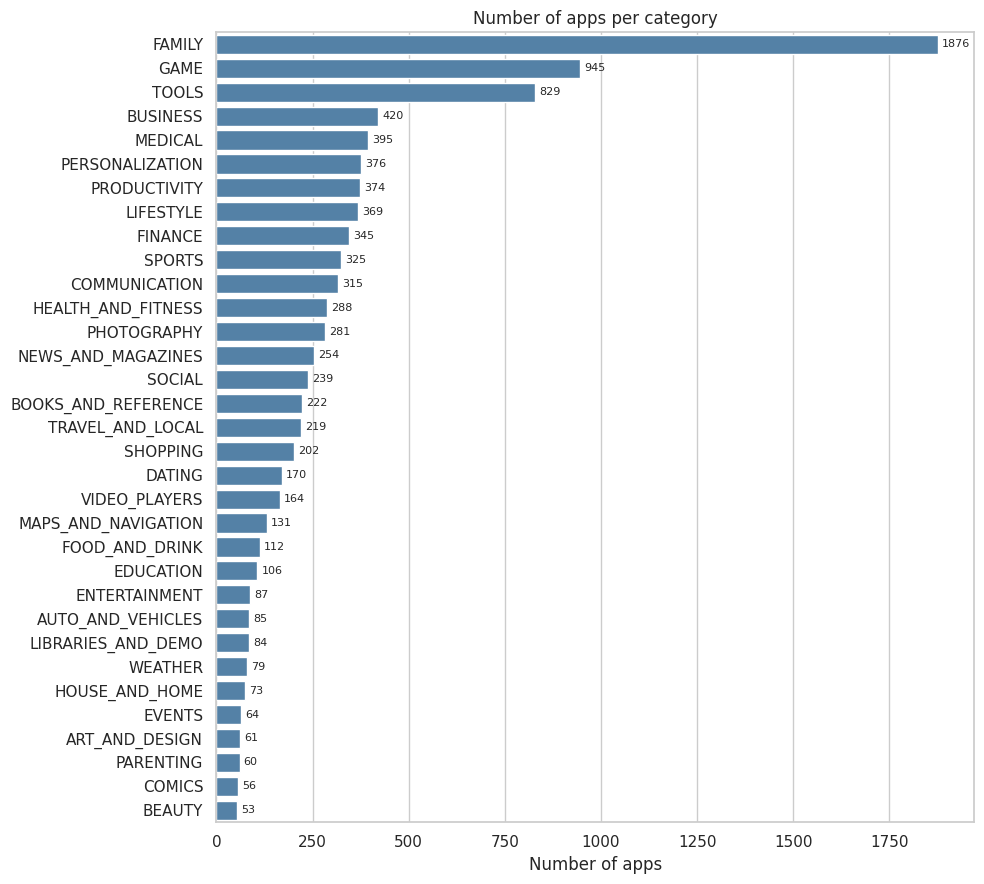

In [ ]:
cat = (apps.groupby("Category")
           .agg(Apps=("App", "count"),
                AvgRating=("Rating", "mean"),
                MedianInstalls=("Installs", "median"),
                TotalInstalls=("Installs", "sum"),
                PaidShare=("Type", lambda s: (s == "Paid").mean() * 100))
           .reset_index())
cat["AppShare"] = cat["Apps"] / cat["Apps"].sum() * 100
cat["InstallsPerApp"] = cat["TotalInstalls"] / cat["Apps"]
cat = cat.sort_values("Apps", ascending=False).reset_index(drop=True)

top5_share = cat["AppShare"].head(5).sum()
print(f"{len(cat)} categories. The top 5 categories hold {top5_share:.0f}% of all apps.")

order = cat["Category"]
plt.figure(figsize=(10, 9))
ax = sns.barplot(data=cat, y="Category", x="Apps", order=order, color="steelblue")
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
plt.title("Number of apps per category")
plt.xlabel("Number of apps")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [ ]:
display(cat[["Category", "Apps", "AppShare", "MedianInstalls", "InstallsPerApp"]]
        .head(10)
        .rename(columns={"AppShare": "Share of apps %", "MedianInstalls": "Median installs",
                         "InstallsPerApp": "Installs per app"}))

,Category,Apps,Share of apps %,Median installs,Installs per app
0,FAMILY,1876,19.42,"50,000.00","3,321,717.75"
1,GAME,945,9.78,"1,000,000.00","14,230,607.85"
2,TOOLS,829,8.58,"50,000.00","9,774,151.89"
3,BUSINESS,420,4.35,"1,000.00","1,659,916.35"
4,MEDICAL,395,4.09,"1,000.00","96,944.50"
5,PERSONALIZATION,376,3.89,"10,000.00","4,075,783.99"
6,PRODUCTIVITY,374,3.87,"100,000.00","15,489,549.11"
7,LIFESTYLE,369,3.82,"10,000.00","1,365,375.44"
8,FINANCE,345,3.57,"10,000.00","1,319,851.40"
9,SPORTS,325,3.36,"100,000.00","3,373,767.69"


**What the data shows:** the market is concentrated. The top 5 of 33 categories hold 46% of all apps, led by `FAMILY` (1,876 apps, 19.4%), `GAME` (945) and `TOOLS` (829). But count alone is not saturation. Compare supply with demand using median installs:
- `FAMILY` and `TOOLS` are crowded **and** modest in demand (median 50,000 installs).
- `BUSINESS` (420 apps) and `MEDICAL` (395 apps) are also crowded and the typical app has only 1,000 installs.
- `GAME` is crowded but demand is strong (median 1,000,000 installs; 57% of games exceed 1M).

## 4. Ratings analysis

8,196 rated apps (85% of all apps)
Mean rating: 4.17 | Median: 4.30 | Share of apps rated 4.0 or above: 77%


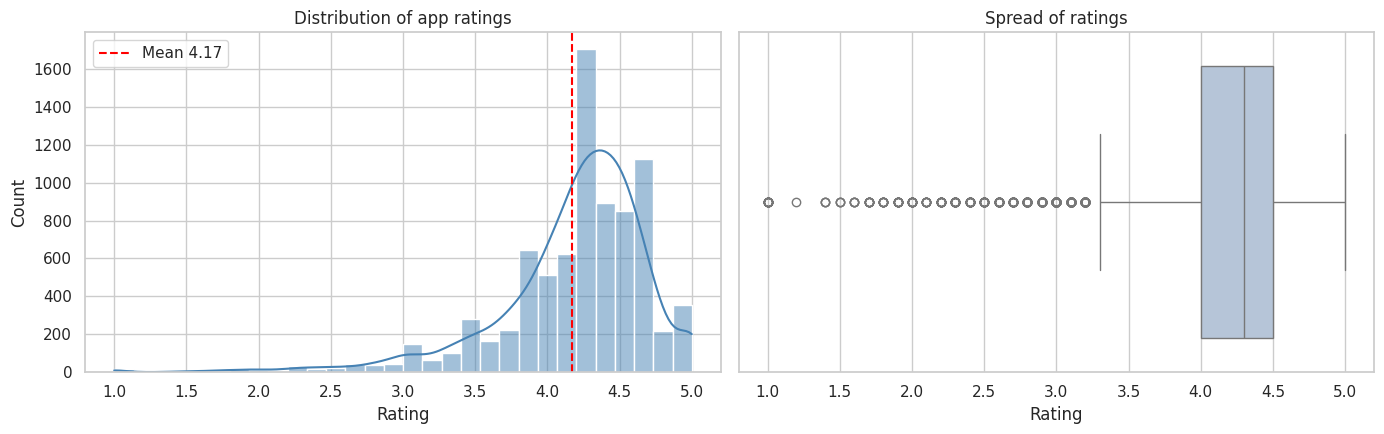

In [ ]:
rated = apps.dropna(subset=["Rating"])
print(f"{len(rated):,} rated apps ({len(rated)/len(apps)*100:.0f}% of all apps)")
print(f"Mean rating: {rated['Rating'].mean():.2f} | Median: {rated['Rating'].median():.2f} | "
      f"Share of apps rated 4.0 or above: {(rated['Rating'] >= 4).mean()*100:.0f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(rated["Rating"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(rated["Rating"].mean(), color="red", ls="--", label=f"Mean {rated['Rating'].mean():.2f}")
axes[0].set_title("Distribution of app ratings")
axes[0].legend()
sns.boxplot(x=rated["Rating"], ax=axes[1], color="lightsteelblue")
axes[1].set_title("Spread of ratings")
plt.tight_layout()
plt.show()

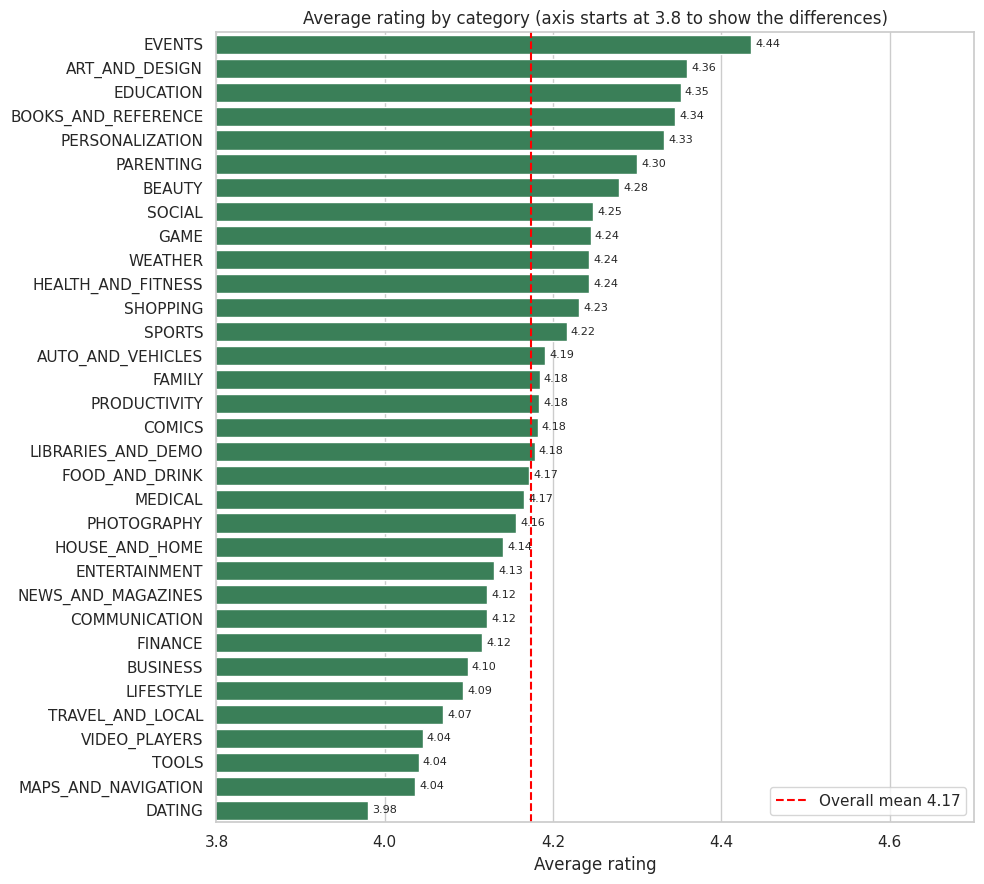

Highest rated : EVENTS (4.44), ART_AND_DESIGN (4.36), EDUCATION (4.35)
Lowest rated  : TOOLS (4.04), MAPS_AND_NAVIGATION (4.04), DATING (3.98)
Spread between best and worst category: 0.46 stars


In [ ]:
cat_rating = (rated.groupby("Category")["Rating"].agg(["mean", "count"])
                   .sort_values("mean", ascending=False).reset_index())
overall = rated["Rating"].mean()

plt.figure(figsize=(10, 9))
ax = sns.barplot(data=cat_rating, y="Category", x="mean", color="seagreen")
ax.axvline(overall, color="red", ls="--", label=f"Overall mean {overall:.2f}")
ax.set_xlim(3.8, 4.7)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3, fontsize=8)
plt.title("Average rating by category (axis starts at 3.8 to show the differences)")
plt.xlabel("Average rating")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.show()

print("Highest rated :", ", ".join(f"{r.Category} ({r['mean']:.2f})" for _, r in cat_rating.head(3).iterrows()))
print("Lowest rated  :", ", ".join(f"{r.Category} ({r['mean']:.2f})" for _, r in cat_rating.tail(3).iterrows()))
print(f"Spread between best and worst category: {cat_rating['mean'].max() - cat_rating['mean'].min():.2f} stars")

**What the data shows:** ratings are high and bunched near the top. The mean is 4.17, the median 4.30, and 77% of rated apps score 4.0 or above, so users are generous and a rating below 4 stands out. Category differences are small (0.46 stars from best to worst): `EVENTS` (4.44), `ART_AND_DESIGN` (4.36) and `EDUCATION` (4.35) lead, while `TOOLS`, `MAPS_AND_NAVIGATION` (both 4.04) and `DATING` (3.98) trail.

## 5. Size and installs

Is a bigger or smaller app downloaded more? `Installs` is a bucket (for example 1,000,000+), so a log scale is used and a rank correlation (Spearman) is reported alongside Pearson.

8,417 apps with a known size and at least one install


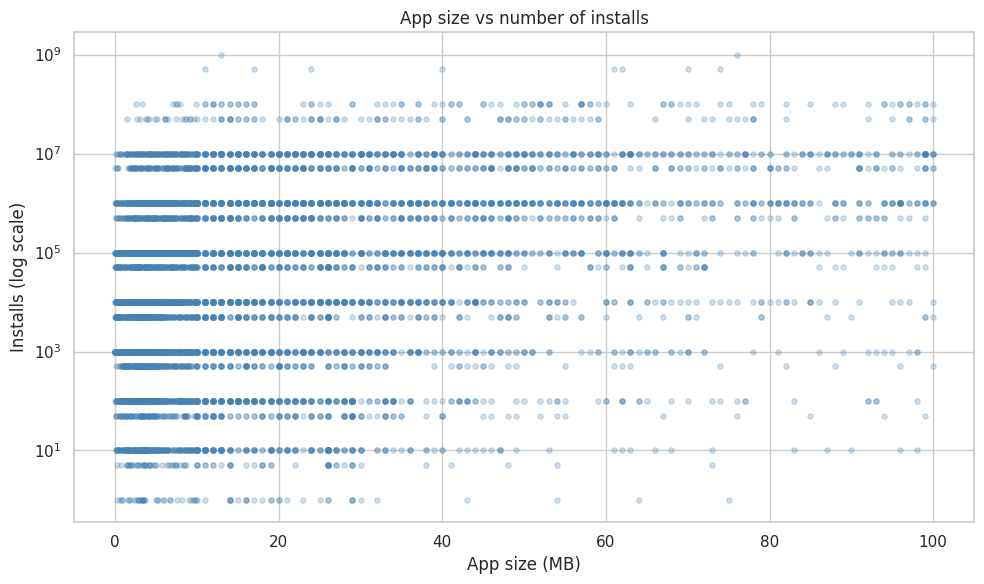

Pearson  correlation (size vs log10 installs): 0.299
Spearman correlation (size vs installs)      : 0.310


In [ ]:
size_df = apps.dropna(subset=["Size_MB"])
size_df = size_df[size_df["Installs"] > 0]
print(f"{len(size_df):,} apps with a known size and at least one install")

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(size_df["Size_MB"], size_df["Installs"], alpha=0.25, s=14, color="steelblue")
ax.set_yscale("log")
ax.set_xlabel("App size (MB)")
ax.set_ylabel("Installs (log scale)")
ax.set_title("App size vs number of installs")
plt.tight_layout()
plt.show()

log_installs = np.log10(size_df["Installs"])
pearson = size_df["Size_MB"].corr(log_installs, method="pearson")
spearman = size_df["Size_MB"].corr(size_df["Installs"], method="spearman")
print(f"Pearson  correlation (size vs log10 installs): {pearson:.3f}")
print(f"Spearman correlation (size vs installs)      : {spearman:.3f}")

,SizeBucket,Apps,MedianInstalls
0,<5 MB,2312,"5,000.00"
1,5-10,1607,"50,000.00"
2,10-20,1533,"50,000.00"
3,20-50,2090,"100,000.00"
4,50-100,875,"1,000,000.00"


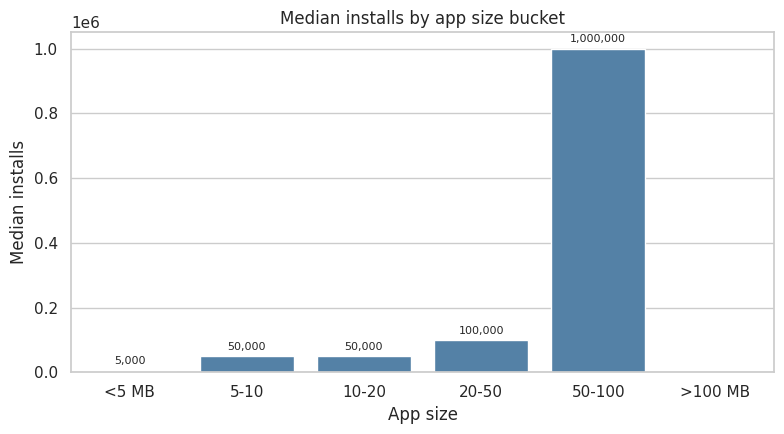

In [ ]:
size_df = size_df.assign(SizeBucket=pd.cut(size_df["Size_MB"], [0, 5, 10, 20, 50, 100, np.inf],
                                           labels=["<5 MB", "5-10", "10-20", "20-50", "50-100", ">100 MB"]))
bucket = (size_df.groupby("SizeBucket", observed=True)["Installs"]
                 .agg(Apps="count", MedianInstalls="median").reset_index())
display(bucket)

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=bucket, x="SizeBucket", y="MedianInstalls", color="steelblue")
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3, fontsize=8)
plt.title("Median installs by app size bucket")
plt.xlabel("App size")
plt.ylabel("Median installs")
plt.tight_layout()
plt.show()

**What the data shows:** there is a **weak-to-moderate positive relationship** (Pearson 0.30, Spearman 0.31). Median installs rise from 5,000 for apps under 5 MB to 1,000,000 for apps of 50-100 MB. Larger apps are typically richer products (games, media tools) with bigger audiences; this is correlation, not proof that adding size causes installs. The scatter also shows huge overlap: small apps can reach millions of installs.

## 6. Pricing analysis

### 6.1 Paid vs free

Type
Free    8905
Paid     754

Paid apps are 7.8% of the market


,MedianInstalls,AvgRating
Type,,
Free,"100,000.00",4.17
Paid,"1,000.00",4.26


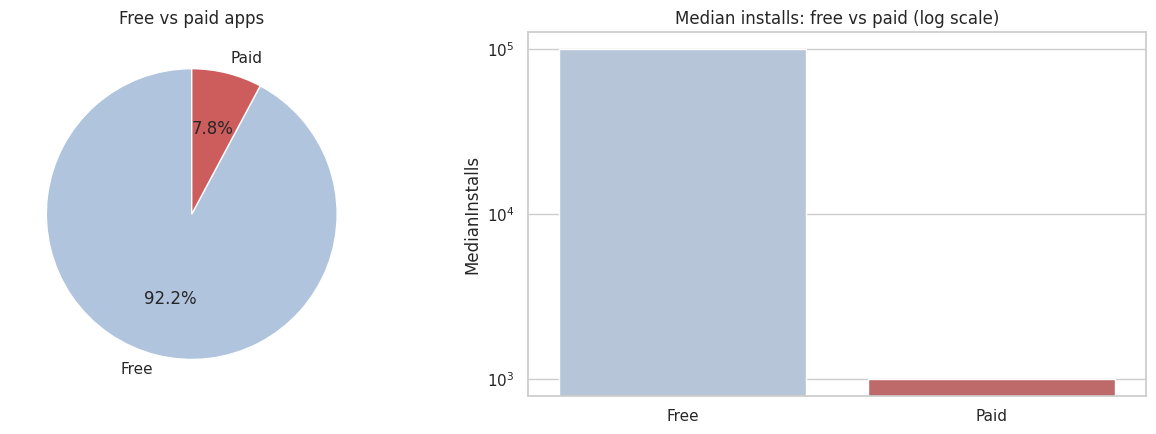

In [ ]:
type_counts = apps["Type"].value_counts()
print(type_counts.to_string())
print(f"\nPaid apps are {type_counts['Paid'] / type_counts.sum() * 100:.1f}% of the market")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].pie(type_counts, labels=type_counts.index, autopct="%1.1f%%", startangle=90,
            colors=["lightsteelblue", "indianred"])
axes[0].set_title("Free vs paid apps")

by_type = apps.groupby("Type").agg(MedianInstalls=("Installs", "median"), AvgRating=("Rating", "mean"))
display(by_type)
sns.barplot(x=by_type.index, y=by_type["MedianInstalls"], ax=axes[1], palette=["lightsteelblue", "indianred"])
axes[1].set_yscale("log")
axes[1].set_title("Median installs: free vs paid (log scale)")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

### 6.2 Price distribution of paid apps

count   754.00
mean     14.06
std      58.82
min       0.99
25%       1.49
50%       2.99
75%       4.99
max     400.00

Paid apps priced above $30: 29 (extreme outliers, e.g. novelty apps at $399.99; hidden from the histogram so it stays readable)


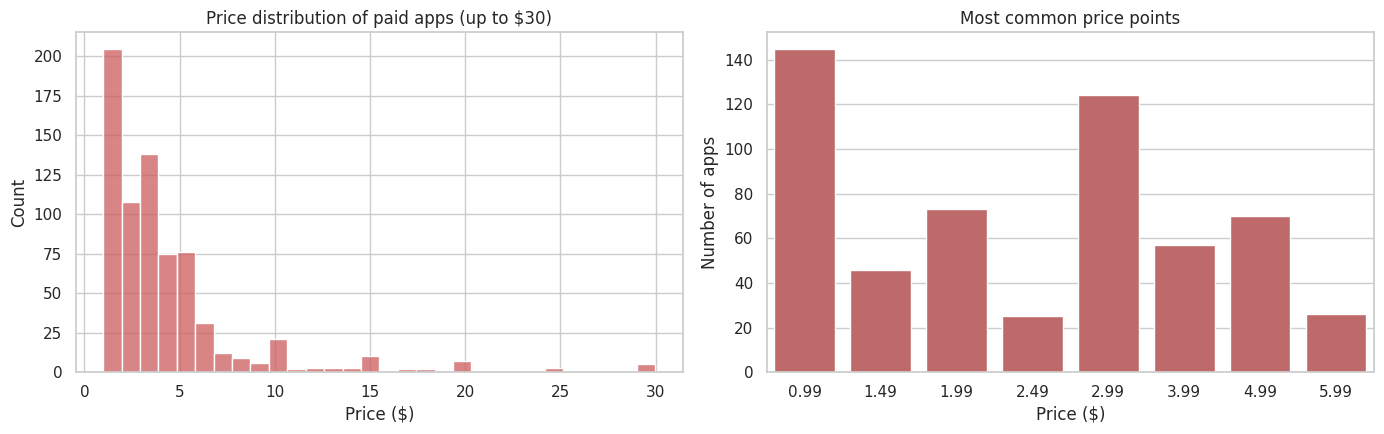

In [ ]:
paid = apps[apps["Type"] == "Paid"].copy()
print(paid["Price"].describe().round(2).to_string())
print(f"\nPaid apps priced above $30: {(paid['Price'] > 30).sum()} "
      f"(extreme outliers, e.g. novelty apps at $399.99; hidden from the histogram so it stays readable)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(paid.loc[paid["Price"] <= 30, "Price"], bins=30, ax=axes[0], color="indianred")
axes[0].set_title("Price distribution of paid apps (up to $30)")
axes[0].set_xlabel("Price ($)")

price_counts = paid["Price"].round(2).value_counts().head(8).sort_index()
sns.barplot(x=price_counts.index.astype(str), y=price_counts.values, ax=axes[1], color="indianred")
axes[1].set_title("Most common price points")
axes[1].set_xlabel("Price ($)")
axes[1].set_ylabel("Number of apps")
plt.tight_layout()
plt.show()

### 6.3 Revenue estimate by category

`Installs` only gives the *minimum* of each bucket, so **estimated revenue = installs x price** is a **lower-bound, gross** estimate (before Google's commission, refunds and taxes). It applies to paid apps only, since the dataset has no in-app purchase or ad revenue.

Total estimated paid-app revenue (lower bound): $291.1 million ($204.4 million excluding the 29 apps priced above $30)


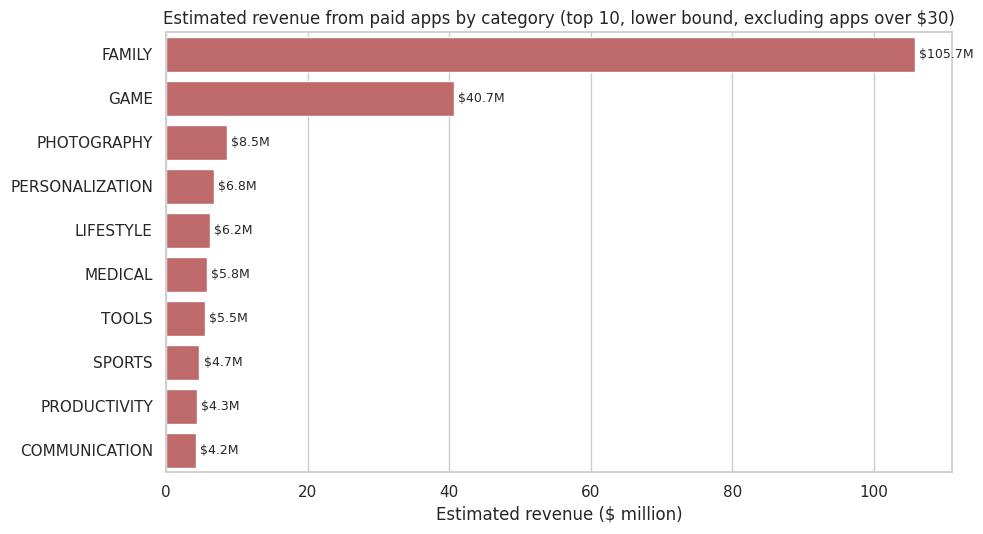

,App,Category,Price,Installs,EstRevenue
1615,Minecraft,FAMILY,6.99,10000000,"69,900,000.00"
3033,Hitman Sniper,GAME,0.99,10000000,"9,900,000.00"
6257,Grand Theft Auto: San Andreas,GAME,6.99,1000000,"6,990,000.00"
2110,Facetune - For Free,PHOTOGRAPHY,5.99,1000000,"5,990,000.00"
4458,Sleep as Android Unlock,LIFESTYLE,5.99,1000000,"5,990,000.00"


The 5 biggest paid apps (excluding apps over $30) account for 48% of estimated paid revenue.


,Category,PaidApps,Avg price ($),Excl. apps over $30 ($),All paid apps ($),Revenue per paid app ($)
0,FAMILY,179.00,4.09,"105,740,416.51","115,680,835.36","590,728.58"
1,GAME,82.00,3.47,"40,688,636.85","40,688,636.85","496,202.89"
2,PHOTOGRAPHY,19.00,6.23,"8,547,767.70","8,547,767.70","449,882.51"
3,PERSONALIZATION,81.00,1.86,"6,796,947.56","6,796,947.56","83,912.93"
4,LIFESTYLE,12.00,3.58,"6,167,159.40","57,583,939.40","513,929.95"
5,MEDICAL,77.00,7.19,"5,763,267.67","5,956,236.67","74,847.63"
6,TOOLS,78.00,3.43,"5,464,820.59","5,464,820.59","70,061.80"
7,SPORTS,24.00,4.17,"4,706,211.95","4,706,211.95","196,092.16"
8,PRODUCTIVITY,27.00,3.55,"4,313,374.95","4,313,374.95","159,754.63"
9,COMMUNICATION,27.00,3.08,"4,247,364.50","4,247,364.50","157,309.80"


In [ ]:
paid["EstRevenue"] = paid["Installs"] * paid["Price"]
# Novelty apps priced at $200-$400 (e.g. "I am rich") would dominate the totals, so both views are shown
rev_all = paid.groupby("Category")["EstRevenue"].sum().rename("All paid apps ($)")
normal = paid[paid["Price"] <= 30]
rev_norm = (normal.groupby("Category")
                  .agg(PaidApps=("App", "count"), EstRevenue=("EstRevenue", "sum"), AvgPrice=("Price", "mean"))
                  .rename(columns={"EstRevenue": "Excl. apps over $30 ($)"}))
rev_cat = rev_norm.join(rev_all, how="outer").sort_values("Excl. apps over $30 ($)", ascending=False).reset_index()
rev_cat["Revenue per paid app ($)"] = rev_cat["Excl. apps over $30 ($)"] / rev_cat["PaidApps"]

print(f"Total estimated paid-app revenue (lower bound): ${paid['EstRevenue'].sum()/1e6:,.1f} million "
      f"(${normal['EstRevenue'].sum()/1e6:,.1f} million excluding the {(paid['Price'] > 30).sum()} apps priced above $30)")

top = rev_cat.head(10)
plt.figure(figsize=(10, 5.5))
ax = sns.barplot(data=top, y="Category", x=top["Excl. apps over $30 ($)"] / 1e6, color="indianred")
ax.bar_label(ax.containers[0], fmt="$%.1fM", padding=3, fontsize=9)
plt.title("Estimated revenue from paid apps by category (top 10, lower bound, excluding apps over $30)")
plt.xlabel("Estimated revenue ($ million)")
plt.ylabel("")
plt.tight_layout()
plt.show()

top_apps = normal.nlargest(5, "EstRevenue")[["App", "Category", "Price", "Installs", "EstRevenue"]]
display(top_apps)
print(f"The 5 biggest paid apps (excluding apps over $30) account for "
      f"{top_apps['EstRevenue'].sum() / normal['EstRevenue'].sum() * 100:.0f}% of estimated paid revenue.")
display(rev_cat.head(10)[["Category", "PaidApps", "AvgPrice", "Excl. apps over $30 ($)", "All paid apps ($)", "Revenue per paid app ($)"]]
        .rename(columns={"AvgPrice": "Avg price ($)"}))

**What the data shows:**
- Paid apps are only **7.8%** of the market (754 of 9,659), and the typical paid app has a median of 1,000 installs versus 100,000 for free apps.
- Paid prices cluster low: the median is $2.99 and 75% cost $4.99 or less. A few novelty apps priced $200-$400 are outliers and are excluded from the charts.
- Estimated paid revenue is a lower bound of about $204 million (excluding apps over $30), and it is **very concentrated**: the 5 biggest paid apps earn 48% of it, and Minecraft alone about a third. `FAMILY` and `GAME` lead by a wide margin.

## 7. Sentiment analysis on user reviews (VADER)

VADER scores each review from -1 (most negative) to +1 (most positive) with a `compound` score. Standard thresholds turn it into a label: **positive** at 0.05 or above, **negative** at -0.05 or below, otherwise **neutral**. VADER is lexicon-based, so it needs no training and no downloads.

,share %,reviews
VADER_Sentiment,,
Positive,68.00,20197
Negative,19.80,5866
Neutral,12.20,3629


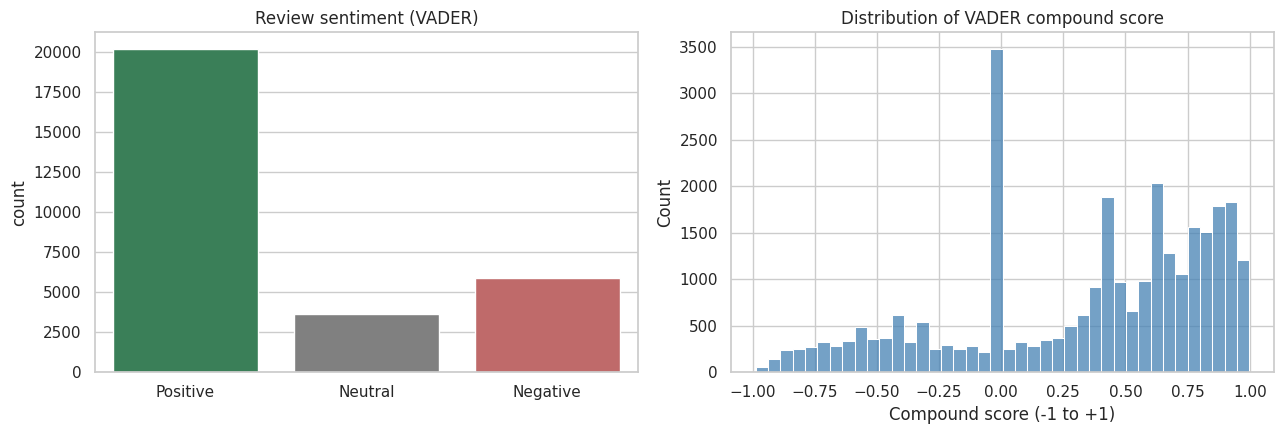

In [ ]:
sia = SentimentIntensityAnalyzer()
reviews["compound"] = reviews["Translated_Review"].astype(str).map(lambda t: sia.polarity_scores(t)["compound"])

def label(score):
    if score >= 0.05:
        return "Positive"
    if score <= -0.05:
        return "Negative"
    return "Neutral"

reviews["VADER_Sentiment"] = reviews["compound"].map(label)

dist = reviews["VADER_Sentiment"].value_counts()
display((dist / dist.sum() * 100).round(1).to_frame("share %").join(dist.rename("reviews")))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = {"Positive": "seagreen", "Neutral": "gray", "Negative": "indianred"}
order_s = ["Positive", "Neutral", "Negative"]
sns.countplot(data=reviews, x="VADER_Sentiment", order=order_s, palette=colors, ax=axes[0])
axes[0].set_title("Review sentiment (VADER)")
axes[0].set_xlabel("")
sns.histplot(reviews["compound"], bins=40, ax=axes[1], color="steelblue")
axes[1].set_title("Distribution of VADER compound score")
axes[1].set_xlabel("Compound score (-1 to +1)")
plt.tight_layout()
plt.show()

**Sanity check:** the dataset ships with its own pre-computed `Sentiment` labels. How closely does VADER agree with them?

In [ ]:
agree = (reviews["VADER_Sentiment"] == reviews["Sentiment"]).mean() * 100
print(f"VADER agrees with the dataset's own labels on {agree:.0f}% of reviews")
display(pd.crosstab(reviews["Sentiment"], reviews["VADER_Sentiment"], normalize="index").mul(100).round(1)
        .rename_axis(index="Dataset label", columns="VADER label"))

VADER agrees with the dataset's own labels on 76% of reviews


VADER label,Negative,Neutral,Positive
Dataset label,,,
Negative,59.20,8.90,31.90
Neutral,17.90,50.10,32.00
Positive,7.10,4.60,88.30


**What the data shows:** 68% of reviews are positive, 20% negative and 12% neutral. VADER agrees with the dataset's own labels on 76% of reviews. Agreement is strongest for positive reviews (88%) and weaker for negative ones (59%); VADER tends to read mixed reviews ("love the idea but it keeps crashing") as positive, so the negative share is probably slightly understated.

## 8. Sentiment by category

Reviews are joined to the apps table to find each app's category. Only categories with enough evidence (at least 100 reviews from at least 10 different apps) are compared, so one or two apps cannot define a whole category.

In [ ]:
MIN_REVIEWS = 100   # at least this many reviews in the category
MIN_APPS = 10       # ...from at least this many different apps, so one app cannot define a category

merged = reviews.merge(apps[["App", "Category"]], on="App", how="inner")
print(f"{len(merged):,} reviews matched to {merged['App'].nunique():,} apps in {merged['Category'].nunique()} categories")

cs = (merged.groupby(["Category", "VADER_Sentiment"]).size().unstack(fill_value=0))
cs["Reviews"] = cs.sum(axis=1)
for s in order_s:
    cs[f"{s} %"] = cs[s] / cs["Reviews"] * 100
cs["Avg compound"] = merged.groupby("Category")["compound"].mean()
cs["Apps reviewed"] = merged.groupby("Category")["App"].nunique()

keep = (cs["Reviews"] >= MIN_REVIEWS) & (cs["Apps reviewed"] >= MIN_APPS)
small = cs[~keep].index.tolist()
cs = cs[keep].sort_values("Positive %", ascending=False)
print(f"Categories compared: {len(cs)}")
print(f"Excluded (under {MIN_REVIEWS} reviews or under {MIN_APPS} apps with reviews): {', '.join(small)}")

display(cs[["Reviews", "Apps reviewed", "Positive %", "Neutral %", "Negative %", "Avg compound"]])

28,250 reviews matched to 816 apps in 33 categories
Categories compared: 23
Excluded (under 100 reviews or under 10 apps with reviews): ART_AND_DESIGN, AUTO_AND_VEHICLES, BEAUTY, COMICS, EVENTS, LIBRARIES_AND_DEMO, MAPS_AND_NAVIGATION, PARENTING, VIDEO_PLAYERS, WEATHER


VADER_Sentiment,Reviews,Apps reviewed,Positive %,Neutral %,Negative %,Avg compound
Category,,,,,,
HEALTH_AND_FITNESS,1621,40,78.47,7.90,13.63,0.48
EDUCATION,519,19,77.65,11.18,11.18,0.46
FOOD_AND_DRINK,583,18,73.76,10.98,15.27,0.43
GAME,3921,84,72.92,5.69,21.40,0.39
FAMILY,2496,70,72.64,10.10,17.27,0.39
BOOKS_AND_REFERENCE,617,16,72.45,11.51,16.05,0.38
PERSONALIZATION,961,34,69.51,12.70,17.79,0.36
PRODUCTIVITY,1135,37,69.25,11.19,19.56,0.37
MEDICAL,1156,33,68.77,14.88,16.35,0.38


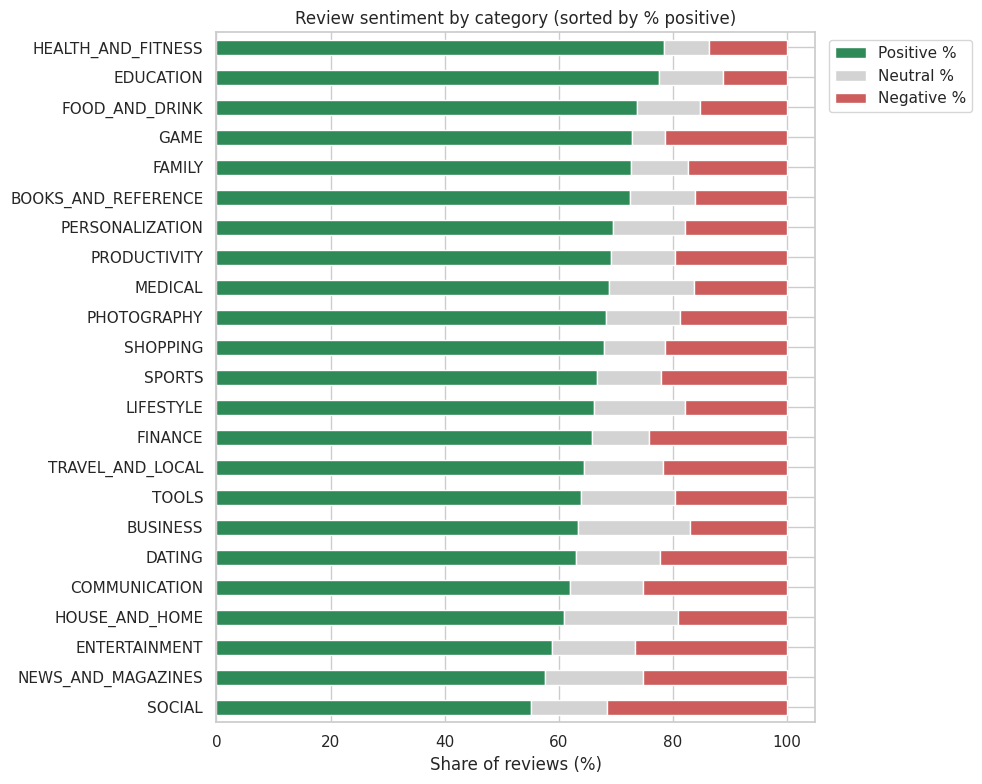

Most positive : HEALTH_AND_FITNESS (78%), EDUCATION (78%), FOOD_AND_DRINK (74%)
Least positive: ENTERTAINMENT (59%), NEWS_AND_MAGAZINES (58%), SOCIAL (55%)
Most negative : SOCIAL (31%), ENTERTAINMENT (27%), NEWS_AND_MAGAZINES (25%)


In [ ]:
plot_df = cs[["Positive %", "Neutral %", "Negative %"]].copy()
ax = plot_df.plot(kind="barh", stacked=True, figsize=(10, 8),
                  color=["seagreen", "lightgray", "indianred"])
ax.invert_yaxis()
ax.set_xlabel("Share of reviews (%)")
ax.set_ylabel("")
ax.set_title("Review sentiment by category (sorted by % positive)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

print("Most positive :", ", ".join(f"{i} ({r['Positive %']:.0f}%)" for i, r in cs.head(3).iterrows()))
print("Least positive:", ", ".join(f"{i} ({r['Positive %']:.0f}%)" for i, r in cs.tail(3).iterrows()))
print("Most negative :", ", ".join(f"{i} ({r['Negative %']:.0f}%)" for i, r in cs.sort_values('Negative %', ascending=False).head(3).iterrows()))

**What the data shows:** `HEALTH_AND_FITNESS` (78% positive), `EDUCATION` (78%) and `FOOD_AND_DRINK` (74%) have the happiest users. `SOCIAL` (55% positive, 31% negative), `NEWS_AND_MAGAZINES` (58%) and `ENTERTAINMENT` (59%) have the least satisfied users. **Caveat:** the reviews file covers only about 800 apps, so category results rest on 15-85 apps each and should be read as indicative, not exact.

## 9. Interactive visualisations (plotly)

Hover over any point or bar for details; click legend entries to hide or show series; drag to zoom and double-click to reset.

In [ ]:
# 9.1 The whole market on one chart: one bubble per category
bubble = cat.copy()
bubble["Total installs (billions)"] = bubble["TotalInstalls"] / 1e9
fig = px.scatter(
    bubble, x="Apps", y="AvgRating", size="Total installs (billions)", color="PaidShare",
    hover_name="Category", size_max=60, color_continuous_scale="RdYlGn_r",
    labels={"Apps": "Number of apps (saturation)", "AvgRating": "Average rating",
            "PaidShare": "% paid apps"},
    title="The Play Store market map: competition vs quality (bubble size = total installs)",
)
fig.update_layout(height=600)
fig.show()

In [ ]:
# 9.2 Sentiment mix by category (interactive stacked bars)
inter = (cs[["Positive %", "Neutral %", "Negative %"]]
         .rename(columns=lambda c: c.replace(" %", ""))
         .reset_index()
         .melt(id_vars="Category", var_name="Sentiment", value_name="Share of reviews (%)"))
fig = px.bar(inter, y="Category", x="Share of reviews (%)", color="Sentiment", orientation="h",
             color_discrete_map={"Positive": "seagreen", "Neutral": "lightgray", "Negative": "indianred"},
             category_orders={"Category": cs.index.tolist(), "Sentiment": order_s},
             title="Review sentiment by category (hover for exact shares)")
fig.update_layout(height=750, yaxis_title="")
fig.show()

In [ ]:
# 9.3 Explore the pricing market: price vs installs for paid apps
px_df = paid[paid["Price"] <= 30].copy()
fig = px.scatter(px_df, x="Price", y="Installs", color="Category", hover_name="App",
                 log_y=True, opacity=0.7,
                 title="Paid apps: price vs installs (log scale, prices up to $30)")
fig.update_layout(height=600)
fig.show()

## 10. Evidence for the conclusion: category opportunity scorecard

Categories with at least 100 apps, ranked by **median installs** (the typical app's success, which is not distorted by a few blockbusters). Sentiment is shown where enough reviews exist.

In [ ]:
score = (cat[cat["Apps"] >= 100][["Category", "Apps", "MedianInstalls", "AvgRating"]]
         .merge(cs[["Positive %", "Negative %"]].reset_index(), on="Category", how="left")
         .sort_values("MedianInstalls", ascending=False)
         .reset_index(drop=True))
score["Share of apps with 1M+ installs %"] = score["Category"].map(
    apps.groupby("Category")["Installs"].apply(lambda s: (s >= 1_000_000).mean() * 100))
display(score.rename(columns={"MedianInstalls": "Median installs", "AvgRating": "Avg rating"}))

big = (apps["Installs"] >= 1_000_000).mean() * 100
print(f"Across the whole store only {big:.0f}% of apps reach 1M+ installs; the median app has {apps['Installs'].median():,.0f}.")

,Category,Apps,Median installs,Avg rating,Positive %,Negative %,Share of apps with 1M+ installs %
0,GAME,945,"1,000,000.00",4.24,72.92,21.40,57.04
1,EDUCATION,106,"1,000,000.00",4.35,77.65,11.18,58.49
2,PHOTOGRAPHY,281,"1,000,000.00",4.16,68.32,18.76,61.57
3,SHOPPING,202,"1,000,000.00",4.23,67.95,21.42,52.48
4,VIDEO_PLAYERS,164,"1,000,000.00",4.04,NaN,NaN,51.83
5,FOOD_AND_DRINK,112,"300,000.00",4.17,73.76,15.27,43.75
6,PRODUCTIVITY,374,"100,000.00",4.18,69.25,19.56,39.30
7,TRAVEL_AND_LOCAL,219,"100,000.00",4.07,64.39,21.79,42.47
8,MAPS_AND_NAVIGATION,131,"100,000.00",4.04,NaN,NaN,41.22
9,SOCIAL,239,"100,000.00",4.25,55.07,31.47,41.84


Across the whole store only 35% of apps reach 1M+ installs; the median app has 100,000.


## 11. Conclusion: 3 data-driven insights for a developer launching a new app

**1. Choose a category by demand per app, not by size. Education stands out as an opportunity.**
`FAMILY`, `TOOLS`, `BUSINESS` and `MEDICAL` hold hundreds of apps each but the typical app gets only 1,000 to 50,000 installs (only 5% of `MEDICAL` and 16% of `BUSINESS` apps reach 1M). `EDUCATION` is the opposite: just 106 apps, yet a median of 1,000,000 installs, 58% of apps above 1M, the third-highest average rating (4.35) and the second-most-positive reviews (78%). `HEALTH_AND_FITNESS` shows similarly happy users (78% positive) with more moderate demand (median 100,000). `GAME` has strong demand (57% above 1M) but is crowded with 945 apps, so it needs a clear differentiator.

**2. Plan for a free app with in-app monetisation, not an upfront price.**
Only 7.8% of apps are paid, and paid apps have a median of 1,000 installs against 100,000 for free apps. Paid revenue is dominated by a few hits (the top 5 earn 48% of the estimated total), so a paid launch is a high-variance bet. If you do charge, stay within the market norm: the median price is $2.99 and 75% of paid apps cost $4.99 or less. (This dataset does not include ad or in-app-purchase revenue, so those still need to be validated separately.)

**3. Quality is the entry ticket, and weak sentiment marks where users are underserved.**
The average rating is 4.17 and 77% of rated apps score 4.0 or higher, so an app below that stands out negatively. Review sentiment is weakest in `SOCIAL` (31% negative), `ENTERTAINMENT` and `NEWS_AND_MAGAZINES` (about 25-27% negative), which suggests unmet needs there for a product with a clearly better experience. Be cautious: `SOCIAL` also has strong incumbents (42% of apps above 1M installs). Do not chase a tiny download size either; size and installs are only weakly related (correlation about 0.3), and users reward richer functionality.

**Limitations:** installs are buckets (lower bounds), the data is a single 2018 snapshot, revenue covers upfront prices only, sentiment covers about 800 apps, and every relationship above is a correlation rather than proof of cause.